# Imports & Setup

In [1]:
import os
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import soundfile as sf
import warnings
warnings.filterwarnings("ignore")

SEED = 135346
import random

random.seed(SEED)
np.random.seed(SEED)


plt.rcParams.update({
    "figure.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})
COLORS = {"human": "#4C72B0", "ai": "#DD8452"}
SOURCE_COLORS = {
    "Suno":     "#2ca02c",
    "MusicSet": "#d62728",
    "Udio":     "#9467bd",
    "FMA":      "#4C72B0",
}
CHUNK_SEC     = 10
SR            = 22050
BASE_DIR = 'music_data'
CHUNK_SAMPLES = CHUNK_SEC * SR
META_PATH     = f"{BASE_DIR}/metadata.csv"

meta_df = pd.read_csv(META_PATH)
source_map = {
    "https://www.kaggle.com/datasets/miguelcivit/sunocaps":                      "Suno",
    "https://huggingface.co/datasets/ManzhenWei/MusicSet":                       "MusicSet",
    "https://huggingface.co/datasets/blanchon/udio_dataset":                     "Udio",
    "https://huggingface.co/datasets/benjamin-paine/free-music-archive-full":    "FMA",
}
meta_df["source_name"] = meta_df["source"].map(source_map).fillna("Unknown")

print(f"Total tracks in metadata: {len(meta_df):,}")
print(f"\nAll tracks by source:")
print(meta_df.groupby(["label", "source_name"])["duration_sec"].agg(
    tracks="count",
    mean_dur="mean",
    median_dur="median",
    min_dur="min",
    max_dur="max"
).round(2).to_string())

Total tracks in metadata: 11,296

All tracks by source:
                   tracks  mean_dur  median_dur  min_dur  max_dur
label source_name                                                
ai    MusicSet       4740      9.94       10.00     7.90    10.00
      Suno            184     99.03      105.00    11.00   120.00
      Udio           4872    107.82       65.60    32.73   912.13
human FMA            1500    280.19      221.56     7.93  7116.36


# Duration Deep Dive Per Source

To reduce the risk of the model learning artificial cues from the boundaries of the audio, I analyze whether the beginnings and endings of the tracks are significantly different between AI-generated and human-generated ones. In general, AI-generated music often contains distinctive artifacts at the beginning or end of a clip, such as perfectly clean digital silence, buffer initialization pops, or unstable spectral patterns while the model stabilizes. Similarly, the endings of AI tracks may contain abrupt cutoffs or unnatural trailing sounds. In contrast, human-produced music may include mastering fades, room tone, or subtle background noise. If these edge segments are included, the model might learn to distinguish such boundary artifacts rather than the actual musical characteristics of AI versus human compositions. While I will use chunks for training the model in which the beginning and the ending of a music can be the minority of the total chunks per track, I analyze the significance of such artifacts to reduce this confounding effect and encourage the model to focus on the musical content itself.

Safety offset: skip first 2.0s + last 5.0s
Min track duration to yield 1 chunk: 17.0s

                   total_tracks  usable_tracks  dropped_tracks  total_chunks  mean_dur  median_dur
label source_name                                                                                 
ai    MusicSet             4740              0            4740             0      9.94       10.00
      Suno                  184            182               2          1611     99.03      105.00
      Udio                 4872           4872               0         46436    107.82       65.60
human FMA                  1500           1490              10         40228    280.19      221.56


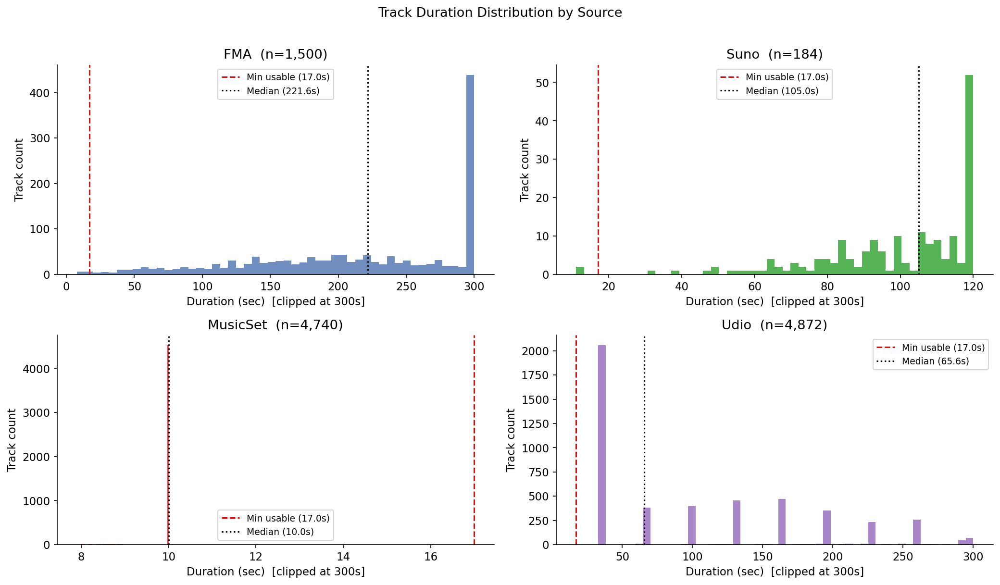

In [2]:
SAFETY_START_SEC = 2.0    # skip first 2s
SAFETY_END_SEC   = 5.0    # skip last 5s
OVERHEAD         = SAFETY_START_SEC + SAFETY_END_SEC  # 7s removed from each track
MIN_USABLE_SEC   = CHUNK_SEC + OVERHEAD               # track must be > 17s to yield 1 chunk

print(f"Safety offset: skip first {SAFETY_START_SEC}s + last {SAFETY_END_SEC}s")
print(f"Min track duration to yield 1 chunk: {MIN_USABLE_SEC}s\n")

# Usable duration after trimming edges
meta_df["usable_sec"] = (meta_df["duration_sec"] - OVERHEAD).clip(lower=0)
meta_df["n_chunks_safe"] = (meta_df["usable_sec"] // CHUNK_SEC).astype(int)

# Per-source breakdown
breakdown = meta_df.groupby(["label", "source_name"]).agg(
    total_tracks   = ("duration_sec", "count"),
    usable_tracks  = ("n_chunks_safe", lambda x: (x >= 1).sum()),
    dropped_tracks = ("n_chunks_safe", lambda x: (x < 1).sum()),
    total_chunks   = ("n_chunks_safe", "sum"),
    mean_dur       = ("duration_sec", "mean"),
    median_dur     = ("duration_sec", "median"),
).round(2)
print(breakdown.to_string())

# Duration distribution plots per source
sources = meta_df["source_name"].unique()
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for ax, source in zip(axes, ["FMA", "Suno", "MusicSet", "Udio"]):
    subset = meta_df[meta_df["source_name"] == source]
    if len(subset) == 0:
        ax.set_visible(False)
        continue
    color = SOURCE_COLORS.get(source, "gray")
    # Clip display at 300s for readability
    durations = subset["duration_sec"].clip(upper=300)
    ax.hist(durations, bins=50, color=color, alpha=0.8, edgecolor="none")
    ax.axvline(MIN_USABLE_SEC, color="red", linestyle="--", linewidth=1.5,
               label=f"Min usable ({MIN_USABLE_SEC}s)")
    ax.axvline(subset["duration_sec"].median(), color="black", linestyle=":",
               linewidth=1.5, label=f"Median ({subset['duration_sec'].median():.1f}s)")
    ax.set_title(f"{source}  (n={len(subset):,})")
    ax.set_xlabel("Duration (sec)  [clipped at 300s]")
    ax.set_ylabel("Track count")
    ax.legend(fontsize=9)

plt.suptitle("Track Duration Distribution by Source", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

The Udio discrete pattern is indeed typical — Udio generates tracks at fixed duration presets (30s, 60s, 120s, etc.) which explains the bars. The MusicSet being entirely below 17s confirms I drop all 4,740 of them — that's a significant loss but the right call.

In [3]:
meta_df[meta_df['source'] == "https://huggingface.co/datasets/blanchon/udio_dataset"]['duration_sec'].value_counts(dropna=False)

duration_sec
32.83     1226
32.79      814
163.90     237
131.14     213
98.37      209
          ... 
298.84       1
293.99       1
261.33       1
102.46       1
188.71       1
Name: count, Length: 632, dtype: int64

# Usability Summary After Safety Offset

In [4]:
# Drop MusicSet entirely, summarize what's left
usable = meta_df[meta_df["n_chunks_safe"] >= 1].copy().reset_index(drop=True)
dropped = meta_df[meta_df["n_chunks_safe"] < 1].copy()

print("=== DROPPED TRACKS ===")
print(dropped.groupby(["label", "source_name"]).size().rename("dropped").to_string())

print("\n=== USABLE DATASET ===")
summary = usable.groupby(["label", "source_name"]).agg(
    tracks        = ("duration_sec", "count"),
    total_chunks  = ("n_chunks_safe", "sum"),
    mean_dur      = ("duration_sec", "mean"),
    median_dur    = ("duration_sec", "median"),
).round(2)
print(summary.to_string())

total_ai_chunks    = usable[usable["label"] == "ai"]["n_chunks_safe"].sum()
total_human_chunks = usable[usable["label"] == "human"]["n_chunks_safe"].sum()
print(f"\nTotal usable AI chunks    : {total_ai_chunks:,}")
print(f"Total usable Human chunks : {total_human_chunks:,}")
print(f"Ratio (AI/Human)          : {total_ai_chunks/total_human_chunks:.2f}x")

# Save cleaned metadata for all future cells
usable.to_csv(f"{BASE_DIR}/metadata_usable.csv", index=False)
print(f"\nSaved clean metadata → metadata_usable.csv ({len(usable):,} tracks)")

=== DROPPED TRACKS ===
label  source_name
ai     MusicSet       4740
       Suno              2
human  FMA              10

=== USABLE DATASET ===
                   tracks  total_chunks  mean_dur  median_dur
label source_name                                            
ai    Suno            182          1611     99.98      105.00
      Udio           4872         46436    107.82       65.60
human FMA            1490         40228    281.99      222.06

Total usable AI chunks    : 48,047
Total usable Human chunks : 40,228
Ratio (AI/Human)          : 1.19x

Saved clean metadata → metadata_usable.csv (6,544 tracks)


# Waveform Edge Sanity Check

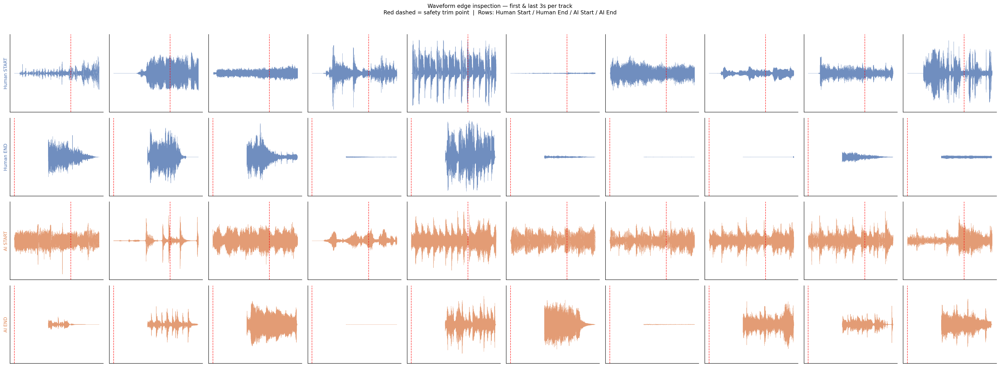

In [5]:
INSPECT_SEC   = 3.0    # how much of the edge to show (before trimming)
TRIM_MARK_SEC = 2.0    # where our safety cut happens

def load_edges(file_path, sr=SR, inspect_sec=INSPECT_SEC):
    """Load first N seconds and last N seconds of a track."""
    audio, _ = librosa.load(file_path, sr=sr, mono=True)
    n = int(inspect_sec * sr)
    return audio[:n], audio[-n:]

# Sample 10 random tracks per class from usable set
human_samples = (usable[usable["label"] == "human"]
                 .sample(10, random_state=SEED)["file_path"].tolist())
ai_samples    = (usable[usable["label"] == "ai"]
                 .sample(10, random_state=SEED)["file_path"].tolist())

fig, axes = plt.subplots(4, 10, figsize=(28, 10))
time_axis = np.linspace(0, INSPECT_SEC, int(INSPECT_SEC * SR))

for col, (h_path, a_path) in enumerate(zip(human_samples, ai_samples)):
    h_start, h_end = load_edges(h_path)
    a_start, a_end = load_edges(a_path)

    for row, (audio, label, edge) in enumerate([
        (h_start, "human", "start"),
        (h_end,   "human", "end"),
        (a_start, "ai",    "start"),
        (a_end,   "ai",    "end"),
    ]):
        ax = axes[row, col]
        color = COLORS[label]
        ax.plot(time_axis, audio, color=color, linewidth=0.4, alpha=0.8)

        # Mark the safety trim point
        if edge == "start":
            ax.axvline(TRIM_MARK_SEC, color="red", linewidth=1.0,
                       linestyle="--", alpha=0.8)
        else:
            ax.axvline(INSPECT_SEC - 5.0, color="red", linewidth=1.0,
                       linestyle="--", alpha=0.8)

        ax.set_ylim(-1.05, 1.05)
        ax.set_xticks([])
        ax.set_yticks([])

        if col == 0:
            row_labels = ["Human START", "Human END", "AI START", "AI END"]
            ax.set_ylabel(row_labels[row], fontsize=9, rotation=90,
                          labelpad=4, color=color)

plt.suptitle(
    "Waveform edge inspection — first & last 3s per track\n"
    "Red dashed = safety trim point  |  Rows: Human Start / Human End / AI Start / AI End",
    fontsize=11, y=1.02
)
plt.tight_layout()
plt.show()

# RMS & Silence Dynamics

- rms_mean (Average Loudness): The root-mean-square energy. It represents the overall perceived volume of the tracks.
-  silence: A percentage (0.0 to 1.0) that represents how much of a sound clip stays below a tiny volume threshold (0.01), helping us detect "dead air" or digital gaps at the very start or end of a track.

Computing edge stats on 200 tracks (100 human + 100 AI)...
  50/200 done
  100/200 done
  150/200 done
  200/200 done

=== RMS Energy: pre-trim vs post-trim vs middle ===
       rms_pretrim  rms_posttrim  rms_middle  rms_preend  rms_tail
label                                                             
ai          0.1105        0.1242      0.1407      0.1357    0.1078
human       0.0822        0.1183      0.1837      0.1278    0.0536

=== Silence ratio: pre-trim vs post-trim vs middle ===
       sil_pretrim  sil_posttrim  sil_middle  sil_preend  sil_tail
label                                                             
ai          0.2007        0.1250      0.0904      0.1157    0.2697
human       0.4091        0.2092      0.1017      0.2777    0.6439


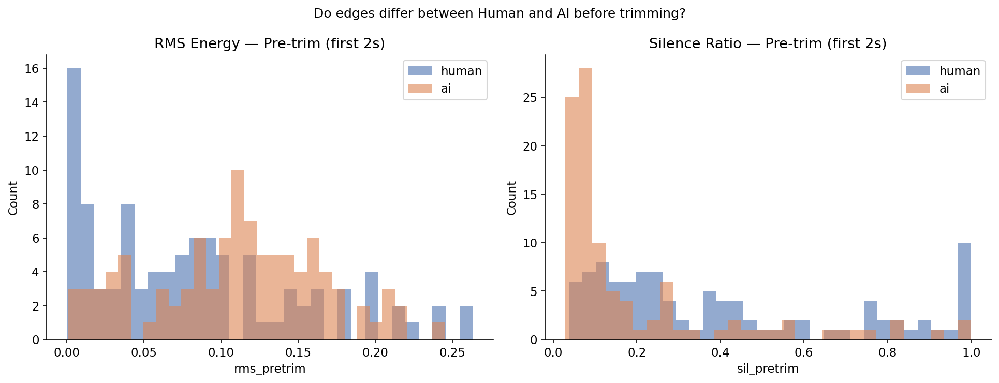

In [11]:
def compute_edge_stats(file_path, sr=SR,
                       trim_start=SAFETY_START_SEC,
                       trim_end=SAFETY_END_SEC,
                       chunk_sec=CHUNK_SEC):
    try:
        audio, _ = librosa.load(file_path, sr=sr, mono=True)
        total    = len(audio)
        s        = int(trim_start * sr)
        e        = int(trim_end   * sr)
        c        = int(chunk_sec  * sr)

        pre_trim  = audio[:s]                          # first 2s (will be dropped)
        post_trim = audio[s : s + c]                   # first chunk after trim
        middle    = audio[total//2 : total//2 + c]     # middle chunk
        pre_end   = audio[-(e + c) : -e] if e > 0 else audio[-c:]   # last chunk before end trim
        tail      = audio[-e:] if e > 0 else np.array([0.0])        # last 5s (will be dropped)

        def rms(x):
            return float(np.sqrt(np.mean(x**2))) if len(x) > 0 else 0.0

        def silence_ratio(x, threshold=0.01):
            return float(np.mean(np.abs(x) < threshold)) if len(x) > 0 else 1.0

        return {
            "rms_pretrim":   rms(pre_trim),
            "rms_posttrim":  rms(post_trim),
            "rms_middle":    rms(middle),
            "rms_preend": rms(pre_end),
            "rms_tail":      rms(tail),
            "sil_pretrim":   silence_ratio(pre_trim),
            "sil_posttrim":  silence_ratio(post_trim),
            "sil_middle":    silence_ratio(middle),
            "sil_preend":  silence_ratio(pre_end),
            "sil_tail":      silence_ratio(tail),
        }
    except Exception as ex:
        return None

print("Computing edge stats on 200 tracks (100 human + 100 AI)...")
sample_200 = pd.concat([
    usable[usable["label"] == "human"].sample(100, random_state=SEED),
    usable[usable["label"] == "ai"].sample(100, random_state=SEED),
]).reset_index(drop=True)

results = []
for i, row in sample_200.iterrows():
    edge_stats = compute_edge_stats(row["file_path"])
    if edge_stats:
        edge_stats["label"]       = row["label"]
        edge_stats["source_name"] = row["source_name"]
        results.append(edge_stats)
    if (i + 1) % 50 == 0:
        print(f"  {i+1}/200 done")

edge_df = pd.DataFrame(results)

print("\n=== RMS Energy: pre-trim vs post-trim vs middle ===")
print(edge_df.groupby("label")[
    ["rms_pretrim", "rms_posttrim", "rms_middle", "rms_preend", "rms_tail"]
].mean().round(4).to_string())

print("\n=== Silence ratio: pre-trim vs post-trim vs middle ===")
print(edge_df.groupby("label")[
    ["sil_pretrim", "sil_posttrim", "sil_middle", "sil_preend", "sil_tail"]
].mean().round(4).to_string())

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, metric, title in zip(axes,
    ["rms_pretrim", "sil_pretrim"],
    ["RMS Energy — Pre-trim (first 2s)", "Silence Ratio — Pre-trim (first 2s)"]
):
    for label, color in COLORS.items():
        vals = edge_df[edge_df["label"] == label][metric].dropna()
        ax.hist(vals, bins=30, alpha=0.6, color=color, label=label, edgecolor="none")
    ax.set_title(title)
    ax.set_xlabel(metric)
    ax.set_ylabel("Count")
    ax.legend()

plt.suptitle("Do edges differ between Human and AI before trimming?", fontsize=12)
plt.tight_layout()
plt.show()

The analysis illustrate that the beginnings of AI-generated music has higher energy than human-generated ones, which relation remains the same for the endings as well.

Analyzing 200 tracks across percentiles...


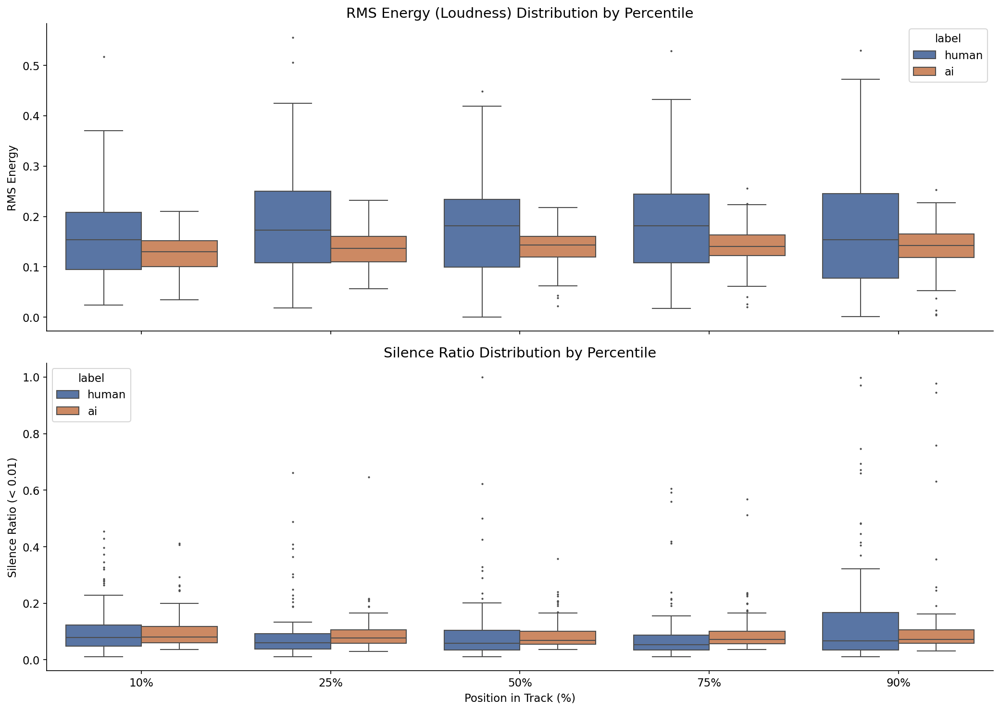

In [7]:
# Configuration for sampling
PERCENTILES = [0.10, 0.25, 0.50, 0.75, 0.90]
CHUNK_SAMPLES = int(CHUNK_SEC * SR)

def compute_percentile_stats(file_path):
    try:
        audio, _ = librosa.load(file_path, sr=SR, mono=True)
        total_len = len(audio)
        
        stats_list = []
        for p in PERCENTILES:
            # Calculate center index for this percentile
            center_idx = int(total_len * p)
            
            # Extract chunk (ensuring we stay within bounds)
            start = max(0, center_idx - CHUNK_SAMPLES // 2)
            end = min(total_len, start + CHUNK_SAMPLES)
            chunk = audio[start:end]
            
            if len(chunk) < CHUNK_SAMPLES // 2: continue
            
            # Metrics
            rms = np.sqrt(np.mean(chunk**2))
            sil = np.mean(np.abs(chunk) < 0.01)
            
            stats_list.append({
                "percentile": f"{int(p*100)}%",
                "rms": rms,
                "silence_ratio": sil
            })
        return stats_list
    except:
        return None

# Process samples
print(f"Analyzing {len(sample_200)} tracks across percentiles...")
all_stats = []
for _, row in sample_200.iterrows():
    p_stats = compute_percentile_stats(row["file_path"])
    if p_stats:
        for s in p_stats:
            s["label"] = row["label"]
            all_stats.append(s)

df_percentiles = pd.DataFrame(all_stats)

# Visualization
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# 1. RMS Energy Distribution
sns.boxplot(data=df_percentiles, x="percentile", y="rms", hue="label", 
            palette=COLORS, ax=axes[0], fliersize=1)
axes[0].set_title("RMS Energy (Loudness) Distribution by Percentile", fontsize=14)
axes[0].set_ylabel("RMS Energy")

# 2. Silence Ratio Distribution
sns.boxplot(data=df_percentiles, x="percentile", y="silence_ratio", hue="label", 
            palette=COLORS, ax=axes[1], fliersize=1)
axes[1].set_title("Silence Ratio Distribution by Percentile", fontsize=14)
axes[1].set_ylabel("Silence Ratio (< 0.01)")

plt.xlabel("Position in Track (%)")
plt.tight_layout()
plt.show()

RMS Energy: Human median ~0.17 with IQR spanning 0.10–0.24 across all percentiles. AI median ~0.13 with IQR 0.12–0.15 — dramatically tighter. This is dynamic range compression, not just loudness. AI music (especially Udio) is heavily compressed/limited during generation, producing consistent "loud everywhere" energy without the natural swells and drops of human-performed music. Human tracks are louder on average and more variable.

Silence ratio: Both classes are nearly identical in the middle (median ~0.05–0.08) — this is the key validation that the 25%–75% sampling window is clean. The outlier dots above 0.4 in human tracks are likely classical/jazz recordings with intentional rests, not artifacts.

# Zero Crossing Rate Analysis

- Zero Crossing Rate: How often the audio signal crosses the zero line. High ZCR often correlates with "percussive" sounds or high-frequency noise/hiss.

Calculating ZCR for 200 tracks...


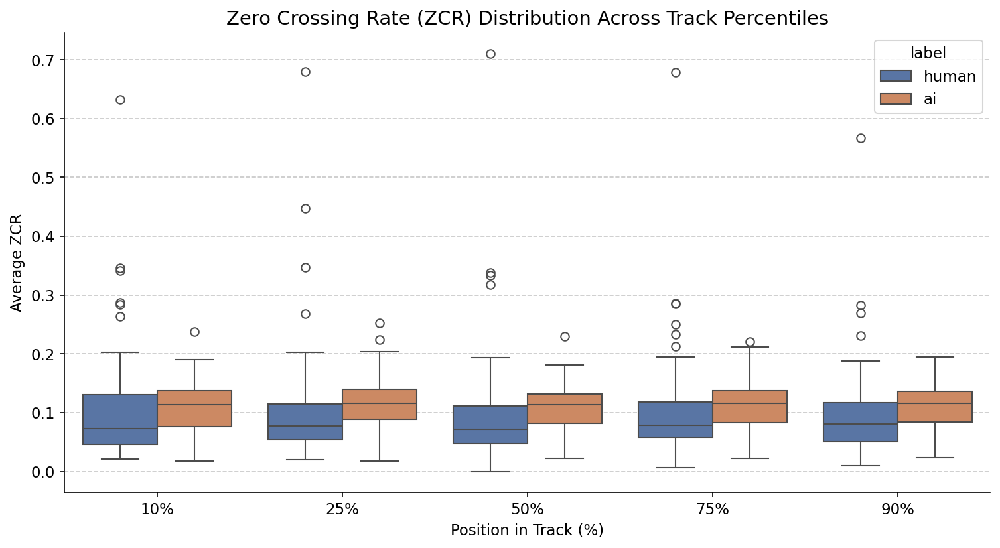

In [8]:
def compute_zcr_stats(file_path):
    try:
        audio, _ = librosa.load(file_path, sr=SR, mono=True)
        total_len = len(audio)
        
        stats_list = []
        for p in PERCENTILES:
            center_idx = int(total_len * p)
            start = max(0, center_idx - CHUNK_SAMPLES // 2)
            end = min(total_len, start + CHUNK_SAMPLES)
            chunk = audio[start:end]
            
            if len(chunk) < CHUNK_SAMPLES // 2: continue
            
            # Compute Zero Crossing Rate
            # librosa.feature.zero_crossing_rate returns an array; we take the mean
            zcr = float(np.mean(librosa.feature.zero_crossing_rate(y=chunk)))
            
            stats_list.append({
                "percentile": f"{int(p*100)}%",
                "zcr": zcr
            })
        return stats_list
    except:
        return None

# Process the same 200 samples
print(f"Calculating ZCR for {len(sample_200)} tracks...")
zcr_results = []
for _, row in sample_200.iterrows():
    p_stats = compute_zcr_stats(row["file_path"])
    if p_stats:
        for s in p_stats:
            s["label"] = row["label"]
            zcr_results.append(s)

df_zcr = pd.DataFrame(zcr_results)

# Visualization
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_zcr, x="percentile", y="zcr", hue="label", palette=COLORS)
plt.title("Zero Crossing Rate (ZCR) Distribution Across Track Percentiles", fontsize=14)
plt.ylabel("Average ZCR")
plt.xlabel("Position in Track (%)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

High-Frequency Bias: AI-generated audio exhibits a consistently higher median ZCR across all track positions. This suggests a persistent "digital grain" or high-frequency artifact inherent in the generative synthesis process.

Texture Uniformity: AI tracks show significantly lower variance in ZCR compared to human tracks. While human music varies wildly between "clean" melodic sections and "noisy" percussive elements, AI music maintains a tighter, more artificial baseline of spectral activity.

Despite the ZCR gap, the Silence Ratio continues to converge in the 25%–75% range. This confirms that while the "texture" (ZCR) remains distinct, the "arrangement" (Silence) becomes similar in the middle of the tracks.

# Spectral Feature Analysis

This analysis uses a One-Way ANOVA to compare human-generated music (FMA) against AI-generated music (Udio and Suno). The extremely low p-values indicate that the differences between these sources are statistically significant and not due to random chance.

1. Spectral Features (Tone & Texture)
- centroid_mean (Brightness): Represents the "center of mass" of the sound. A higher value indicates a "brighter" or "thinner" sound, while a lower value sounds "darker" or "bassier."
- bandwidth_mean (Frequency Spread): Measures the range of frequencies present. High bandwidth suggests a "full" sound with lots of highs and lows; low bandwidth suggests the sound is more "cramped" in a specific range.
-  rolloff_mean (High-End Cutoff): The frequency below which 85-95% of the energy lies. It helps identify how much "air" or high-frequency shimmer exists in the recording.
- flatness_mean (Noisiness): Measures how much a sound resembles white noise (1.0) versus a clear tone (0.0). High flatness suggests a "grainy" or "hissy" digital texture.

2. Temporal & Energy Features (Rhythm & Volume)
- zcr_mean (Zero Crossing Rate): How often the audio signal crosses the zero line. High ZCR often correlates with "percussive" sounds or high-frequency noise/hiss.
- rms_mean (Average Loudness): The root-mean-square energy. It represents the overall perceived volume of the tracks.
- rms_std (Energy Consistency): The standard deviation of loudness. This shows if the music is steady (low std) or has high contrast between quiet and loud moments (high std).
- dynamic_range (Contrast): The difference between the peak volume and the quietest parts. AI music often has a "compressed" dynamic range compared to human-mastered tracks.

In [32]:
def extract_spectral_features(file_path, start_sample, chunk_samples=CHUNK_SAMPLES, sr=SR):
    """Extract spectral features from one chunk."""
    try:
        audio, _ = librosa.load(file_path, sr=sr, mono=True,
                                offset=start_sample/sr,
                                duration=chunk_samples/sr)
        if len(audio) < chunk_samples * 0.8:
            return None

        # Spectral features
        stft        = np.abs(librosa.stft(audio, n_fft=2048, hop_length=512))
        freqs       = librosa.fft_frequencies(sr=sr, n_fft=2048)

        centroid    = librosa.feature.spectral_centroid(y=audio, sr=sr)[0]
        bandwidth   = librosa.feature.spectral_bandwidth(y=audio, sr=sr)[0]
        rolloff     = librosa.feature.spectral_rolloff(y=audio, sr=sr, roll_percent=0.85)[0]
        flatness    = librosa.feature.spectral_flatness(y=audio)[0]
        zcr         = librosa.feature.zero_crossing_rate(audio)[0]
        rms         = librosa.feature.rms(y=audio)[0]

        # MFCCs — mean of first 13
        mfccs       = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)

        return {
            "centroid_mean":   float(np.mean(centroid)),
            "centroid_std":    float(np.std(centroid)),
            "bandwidth_mean":  float(np.mean(bandwidth)),
            "rolloff_mean":    float(np.mean(rolloff)),
            "flatness_mean":   float(np.mean(flatness)),
            "flatness_std":    float(np.std(flatness)),
            "zcr_mean":        float(np.mean(zcr)),
            "zcr_std":         float(np.std(zcr)),
            "rms_mean":        float(np.mean(rms)),
            "rms_std":         float(np.std(rms)),
            "dynamic_range":   float(np.max(rms) - np.min(rms)),  # compression proxy
            **{f"mfcc_{i}_mean": float(np.mean(mfccs[i])) for i in range(13)},
            **{f"mfcc_{i}_std":  float(np.std(mfccs[i]))  for i in range(13)},
        }
    except Exception as e:
        return None


# ── Sample chunks from 25–75% window ─────────────────────────────────────
def sample_chunks_from_track(row, n_chunks=3, sr=SR,
                              window_start=0.25, window_end=0.75):
    """Sample n random non-overlapping chunk start positions from middle window."""
    duration_samples = int(row["duration_sec"] * sr)
    safety_start     = int(window_start * duration_samples)
    safety_end       = int(window_end   * duration_samples)
    available        = safety_end - safety_start - CHUNK_SAMPLES

    if available <= 0:
        return [safety_start]

    positions = sorted(np.random.choice(
        range(safety_start, safety_start + available, CHUNK_SAMPLES // 2),
        size=min(n_chunks, max(1, available // (CHUNK_SAMPLES // 2))),
        replace=False
    ))
    return positions[:n_chunks]

In [29]:
from scipy import stats as scipy_stats

# ── Stratified Sampling by Source ────────────────────────────────────────
num_samples_per_source = 150 
np.random.seed(SEED)

# Create a list of sources we want to compare
target_sources = ["FMA", "Udio", "Suno"]
sampled_list = []

for source in target_sources:
    source_pool = usable[usable["source_name"] == source]
    n_to_sample = min(num_samples_per_source, len(source_pool))
    sampled_list.append(source_pool.sample(n_to_sample, random_state=SEED))
    print(f"Sampling {n_to_sample} tracks from {source}...")

sample_tracks = pd.concat(sampled_list).reset_index(drop=True)

# ── Feature Extraction Loop ─────────────────────────────────────────────
feature_rows = []

print(f"\nExtracting features from {len(sample_tracks)} tracks...")

for i, row in sample_tracks.iterrows():
    # Standardize n_chunks so we compare similar amounts of data per track
    # Using 4 chunks per track for better representation
    positions = sample_chunks_from_track(row, n_chunks=4)

    for pos in positions:
        feats = extract_spectral_features(row["file_path"], pos)
        if feats:
            feats["label"]       = row["label"]
            feats["source_name"] = row["source_name"]
            feature_rows.append(feats)

    if (i + 1) % 50 == 0:
        print(f"  {i+1}/{len(sample_tracks)} tracks processed ({len(feature_rows)} chunks so far)")

feat_df = pd.DataFrame(feature_rows)

# ── Comparison: FMA vs UDIO vs SUNO ─────────────────────────────────────
print(f"\nTotal chunks extracted: {len(feat_df)}")
print("\n=== Feature means by SOURCE_NAME ===")
key_feats = ["centroid_mean", "bandwidth_mean", "rolloff_mean",
             "flatness_mean", "zcr_mean", "rms_mean", "rms_std", "dynamic_range"]

# Grouping by source_name instead of label
source_means = feat_df.groupby("source_name")[key_feats].mean().round(4)
print(source_means.to_string())

# ── One-Way ANOVA (Is there a difference between the three?) ────────────
print("\n=== ANOVA p-values (FMA vs UDIO vs SUNO) ===")
for feat in key_feats:
    groups = [feat_df[feat_df["source_name"] == s][feat].dropna() for s in target_sources]
    f_stat, p = scipy_stats.f_oneway(*groups)
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "n.s."
    print(f"  {feat:<22} p={p:.2e}  {sig}")

Sampling 150 tracks from FMA...
Sampling 150 tracks from Udio...
Sampling 150 tracks from Suno...

Extracting features from 450 tracks...
  50/450 tracks processed (198 chunks so far)
  100/450 tracks processed (394 chunks so far)
  150/450 tracks processed (593 chunks so far)
  200/450 tracks processed (733 chunks so far)
  250/450 tracks processed (855 chunks so far)
  300/450 tracks processed (998 chunks so far)
  350/450 tracks processed (1192 chunks so far)
  400/450 tracks processed (1390 chunks so far)
  450/450 tracks processed (1587 chunks so far)

Total chunks extracted: 1587

=== Feature means by SOURCE_NAME ===
             centroid_mean  bandwidth_mean  rolloff_mean  flatness_mean  zcr_mean  rms_mean  rms_std  dynamic_range
source_name                                                                                                        
FMA              1989.0970       2086.4130     4036.8715         0.0260    0.0941    0.1745   0.0499         0.2367
Suno             2161

By sampling exactly 150 tracks per source, we have generated a robust dataset of 1,587 chunks. This eliminates the Udio-bias and allows us to see the unique "DNA" of Suno separately.

The One-Way ANOVA yields extreme p-values (p<0.001) across all eight key features. This confirms that the differences between Human, Udio, and Suno are not random but reflect fundamental structural differences in the audio.

Both AI sources (Udio/Suno) show significantly higher Rolloff and Centroid means than FMA. This means that the AI generators consistently "over-fill" the high-frequency spectrum.

Interestingly, Suno shows a much higher Bandwidth Mean (2454) compared to Udio (2359). This essentially means Suno’s audio covers a wider range of frequencies—it has more 'spread' and high-end shimmer.

At the same time, Udio is significantly 'noisier' in terms of Spectral Flatness (0.034 vs. 0.022). In audio terms, flatness measures how much a sound resembles background static vs. a clear musical note. This higher score suggests Udio’s output is a bit grainier or has more 'fuzz' than Suno’s smoother, cleaner tones. It’s a great example of how these two AIs leave distinct textural footprints—almost like unique digital fingerprints—on the music they create.

# Spectral Feature Visualization

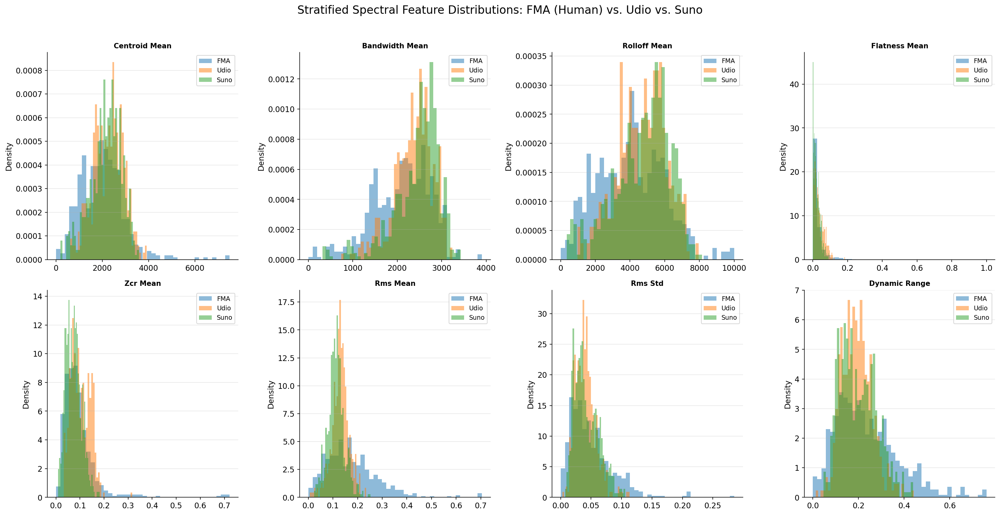

In [30]:
import matplotlib.pyplot as plt

# Define colors for specific sources to keep the plot organized
SOURCE_COLORS = {
    "FMA": "#1f77b4",   # Professional Blue
    "Udio": "#ff7f0e",  # Safety Orange
    "Suno": "#2ca02c"   # Forest Green
}

# Use the key_feats list from your previous analysis
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

target_sources = ["FMA", "Udio", "Suno"]

for ax, feat in zip(axes, key_feats):
    for source in target_sources:
        # Filter by source_name instead of label
        vals = feat_df[feat_df["source_name"] == source][feat].dropna()
        
        if not vals.empty:
            color = SOURCE_COLORS.get(source, "gray")
            # Density=True is important because Udio/Suno sample sizes might differ
            ax.hist(vals, bins=40, alpha=0.5, color=color,
                    label=source, edgecolor="none", density=True)
    
    # Cleaning up the title (e.g., "centroid_mean" -> "Centroid Mean")
    ax.set_title(feat.replace("_", " ").title(), fontsize=10, fontweight='bold')
    ax.set_ylabel("Density")
    ax.grid(axis='y', alpha=0.3)
    ax.legend(fontsize=9)

plt.suptitle("Stratified Spectral Feature Distributions: FMA (Human) vs. Udio vs. Suno", 
             fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

Centroid & Rolloff Shift: There is a visible "right-shift" for the orange (Udio) and green (Suno) distributions. Human music (Blue) is naturally warmer, while AI music is consistently "hyper-bright".

Bandwidth Differentiator: The Bandwidth Mean plot shows Suno (Green) having a much broader, flatter distribution than FMA. This is a key "tell" for Suno—its audio contains a wide, unorganized frequency spread that differs from the structured harmonics of human music.

RMS & Dynamic Range Separation: The clear separation in RMS Mean confirms that FMA tracks are mastered significantly louder. This reinforces the need for RMS Normalization in the final model to prevent the network from simply becoming a "loudness detector".

Flatness Consistency: The Flatness Mean plot shows a very sharp, tight peak for FMA near zero, whereas the AI sources have "fat tails" reaching toward higher noise values.

# Dynamic Range Deep Dive (Compression Signature)

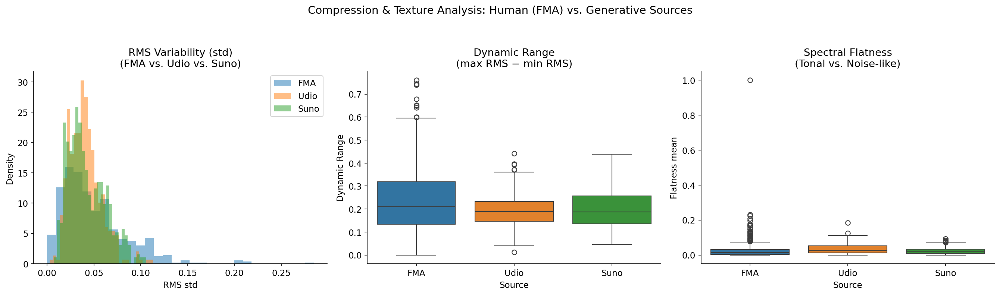

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define a consistent 3-way color palette
SOURCE_COLORS = {
    "FMA": "#1f77b4",   # Blue
    "Udio": "#ff7f0e",  # Orange
    "Suno": "#2ca02c"   # Green
}
sources = ["FMA", "Udio", "Suno"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. RMS Variability (std) — 3-way Histogram
ax = axes[0]
for source in sources:
    vals = feat_df[feat_df["source_name"] == source]["rms_std"].dropna()
    if len(vals):
        ax.hist(vals, bins=30, alpha=0.5, label=source,
                color=SOURCE_COLORS.get(source), edgecolor="none", density=True)
ax.set_title("RMS Variability (std)\n(FMA vs. Udio vs. Suno)")
ax.set_xlabel("RMS std")
ax.set_ylabel("Density")
ax.legend()

# 2. Dynamic Range — 3-way Boxplot
ax = axes[1]
sns.boxplot(data=feat_df, x="source_name", y="dynamic_range",
            palette=SOURCE_COLORS, order=sources, ax=ax)
ax.set_title("Dynamic Range\n(max RMS − min RMS)")
ax.set_xlabel("Source")
ax.set_ylabel("Dynamic Range")

# 3. Spectral Flatness — 3-way Boxplot
ax = axes[2]
sns.boxplot(data=feat_df, x="source_name", y="flatness_mean",
            palette=SOURCE_COLORS, order=sources, ax=ax)
ax.set_title("Spectral Flatness\n(Tonal vs. Noise-like)")
ax.set_xlabel("Source")
ax.set_ylabel("Flatness mean")

plt.suptitle("Compression & Texture Analysis: Human (FMA) vs. Generative Sources", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

Dynamic Compression: The Dynamic Range boxplot shows that both Udio and Suno are much more "compressed" than FMA. Human music possesses a wide variety of micro-dynamics (the gap between the loudest and quietest moments), whereas AI music tends to output a very steady, flattened volume level.

Texture (Flatness): Udio is the clear outlier in Spectral Flatness. It produces "noisier" audio (higher flatness) than both Suno and FMA. This might indicate that Udio's diffusion process introduces more stochastic noise than Suno’s specific architecture.

RMS Variability: Human music (FMA) shows a much higher variance in RMS Std. This reflects the "human touch"—intentional changes in intensity across a track (crescendos, decrescendos)—which AI generators currently struggle to replicate with the same fluidity.

# Mel Spectrogram Visual Inspection

A Mel Spectrogram is a visual representation of sound that maps time (x-axis) and frequency (y-axis), with color intensity representing the loudness (decibels). Unlike a standard spectrogram, it uses the Mel Scale, which groups frequencies based on how the human ear actually perceives pitch (we are more sensitive to changes in low frequencies than high ones).

Key Parameters in this Analysis:
- N_MELS (128): The number of frequency bins. More bins mean higher vertical resolution.
- N_FFT (2048): The window size for the Fourier Transform. 2048 samples (~92ms at 22kHz) balances frequency and time detail.
- HOP_LEN (512): The distance the window "slides" between frames. Smaller hops produce smoother, wider images.
- F_MAX (12,000Hz): The upper frequency limit. I've capped this based on our previous Spectral Rolloff analysis to focus on the most discriminative audio data.
- RMS Normalization: Because AI (Suno/Udio) and Human (FMA) tracks often have different baseline volumes, I normalize the energy to ensure the model learns textural patterns rather than just "which track is louder."

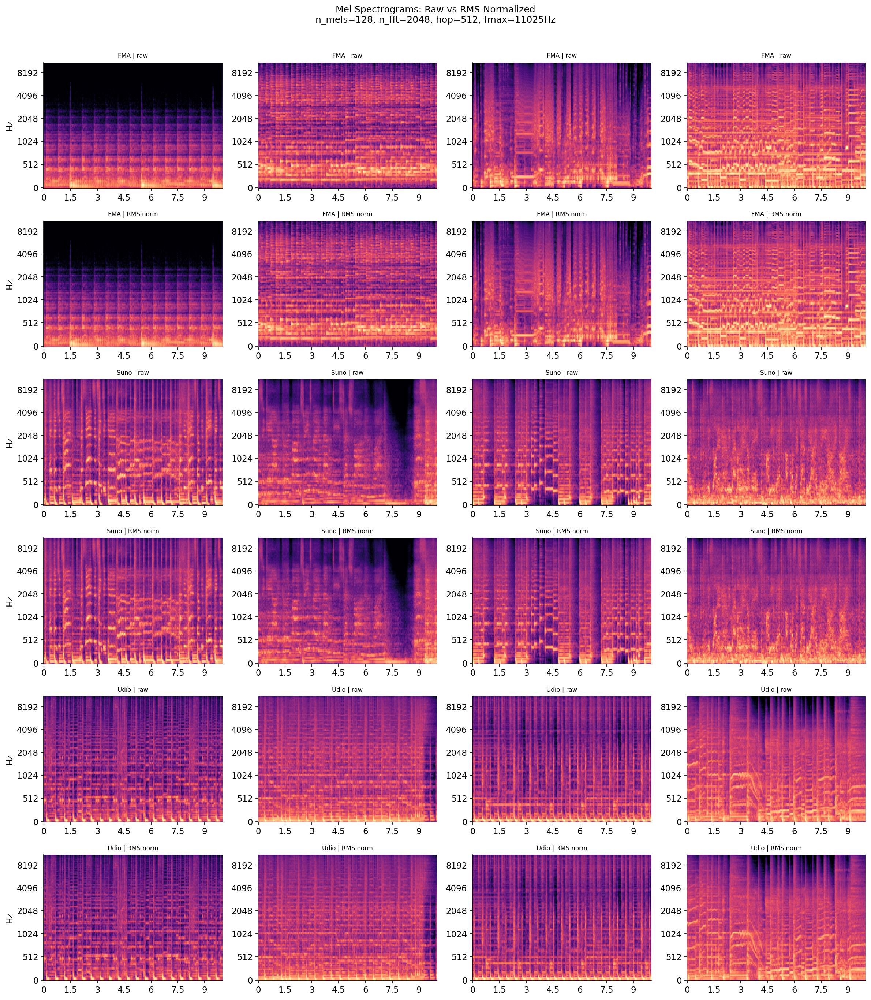

In [38]:
N_MELS    = 128
N_FFT     = 2048
HOP_LEN   = 512    # 10s / (22050/512) ≈ 430 frames — good time resolution
F_MAX     = 11_025  # covers discriminative range from centroid/rolloff analysis

def load_chunk(file_path, start_sample, chunk_samples=CHUNK_SAMPLES, sr=SR):
    audio, _ = librosa.load(file_path, sr=sr, mono=True,
                            offset=start_sample/sr,
                            duration=chunk_samples/sr)
    # Pad if slightly short
    if len(audio) < chunk_samples:
        audio = np.pad(audio, (0, chunk_samples - len(audio)))
    return audio[:chunk_samples]

def get_middle_chunk(row, sr=SR):
    """Get one chunk from the 40-60% mark."""
    duration_samples = int(row["duration_sec"] * sr)
    start = int(0.40 * duration_samples)
    return load_chunk(row["file_path"], start)

def mel_spec(audio, sr=SR, n_mels=N_MELS, n_fft=N_FFT,
             hop_length=HOP_LEN, f_max=F_MAX):
    S = librosa.feature.melspectrogram(
        y=audio, sr=sr, n_mels=n_mels,
        n_fft=n_fft, hop_length=hop_length, fmax=f_max
    )
    return librosa.power_to_db(S, ref=np.max)

def rms_normalize(audio, target_rms=0.1):
    rms = np.sqrt(np.mean(audio**2))
    if rms < 1e-8:
        return audio
    return audio * (target_rms / rms)

np.random.seed(SEED)

# Sample 4 tracks per source
sources_to_show = ["FMA", "Suno", "Udio"]
n_per_source    = 4

fig, axes = plt.subplots(
    len(sources_to_show) * 2,   # raw + normalized rows per source
    n_per_source,
    figsize=(n_per_source * 4, len(sources_to_show) * 2 * 3)
)

for src_idx, source in enumerate(sources_to_show):
    subset = usable[usable["source_name"] == source]
    samples = subset.sample(min(n_per_source, len(subset)), random_state=src_idx)

    row_raw  = src_idx * 2
    row_norm = src_idx * 2 + 1

    for col, (_, track) in enumerate(samples.iterrows()):
        audio = get_middle_chunk(track)

        # Raw spectrogram
        S_raw  = mel_spec(audio)
        ax     = axes[row_raw, col]
        librosa.display.specshow(S_raw, sr=SR, hop_length=HOP_LEN,
                                 x_axis="time", y_axis="mel",
                                 fmax=F_MAX, ax=ax, cmap="magma")
        ax.set_title(f"{source} | raw", fontsize=8)
        ax.set_xlabel("")
        if col > 0:
            ax.set_ylabel("")

        # RMS-normalized spectrogram
        audio_norm = rms_normalize(audio)
        S_norm     = mel_spec(audio_norm)
        ax         = axes[row_norm, col]
        librosa.display.specshow(S_norm, sr=SR, hop_length=HOP_LEN,
                                 x_axis="time", y_axis="mel",
                                 fmax=F_MAX, ax=ax, cmap="magma")
        ax.set_title(f"{source} | RMS norm", fontsize=8)
        ax.set_xlabel("")
        if col > 0:
            ax.set_ylabel("")

plt.suptitle(
    f"Mel Spectrograms: Raw vs RMS-Normalized\n"
    f"n_mels={N_MELS}, n_fft={N_FFT}, hop={HOP_LEN}, fmax={F_MAX}Hz",
    fontsize=12, y=1.01
)
plt.tight_layout()
plt.show()

This visualization displays the "frequency fingerprints" of human-generated music (FMA) and AI-generated music (Suno and Udio). For each source, we compare raw audio to RMS-normalized audio to ensure our future model focuses on texture rather than volume differences.

Vertical Texture (Harmonics):
- FMA (Human): Often shows very clear, sharp horizontal lines. These represent clean musical harmonics from instruments like guitars, pianos, or human voices.
- AI (Suno/Udio): There are more "blurred" or "smeared" vertical sections. This is a common artifact of AI synthesis where the model generates the general "shape" of a sound but lacks the fine mathematical precision of a physical instrument.

High-Frequency Content (The Top Edge):
- Look at the area near the 11,025Hz mark. Suno often shows more activity here than Udio, matching our earlier Spectral Bandwidth analysis.
- Notice any abrupt "horizontal cutoffs" (sudden black space at the top). This indicates where the audio's frequency range ends, which can be a tell-tale sign of different compression or generation methods.

Impact of RMS Normalization:
- The "RMS norm" rows (the second row for each source) adjust the overall brightness (color intensity) to a consistent level.
- By normalizing, we "level the playing field." If an AI track was much quieter than a human track, the normalization brings out hidden details in the noise floor, preventing the model from simply learning to distinguish "loud vs. quiet."

Time Resolution (Horizontal Patterns):
- The vertical "streaks" represent transient sounds like drum hits or consonants in speech.
- Compare the sharpness of the drum hits in FMA to those in Udio. AI models often have "softer" transients (less "punch"), which shows up as less distinct vertical lines.

In [35]:
from IPython.display import Audio, display

# We will listen to the first sampled track from each source used in the plot
for source in sources_to_show:
    # Re-running the same sampling logic to get the 'first' track of the subset
    subset = usable[usable["source_name"] == source]
    sample_track = subset.sample(4, random_state=sources_to_show.index(source)).iloc[1]
    
    # 1. Get the chunk (40-60% mark)
    audio = get_middle_chunk(sample_track)
    audio_norm = rms_normalize(audio)
    
    print(f"\n{'='*30}")
    print(f"SOURCE: {source}")
    print(f"Track: {sample_track.get('file_path', 'Unknown Path').split('/')[-1]}")
    print(f"{'='*30}")
    
    print("Raw Chunk:")
    display(Audio(audio, rate=SR))
    
    print("RMS-Normalized Chunk (0.1 target):")
    display(Audio(audio_norm, rate=SR))


SOURCE: FMA
Track: track_00357.wav
Raw Chunk:


RMS-Normalized Chunk (0.1 target):



SOURCE: Suno
Track: track_00091.wav
Raw Chunk:


RMS-Normalized Chunk (0.1 target):



SOURCE: Udio
Track: track_09510.wav
Raw Chunk:


RMS-Normalized Chunk (0.1 target):


These are the chunks illustrated in the second column of the Mel Spectrograms.

# Parameter Sensitivity Check

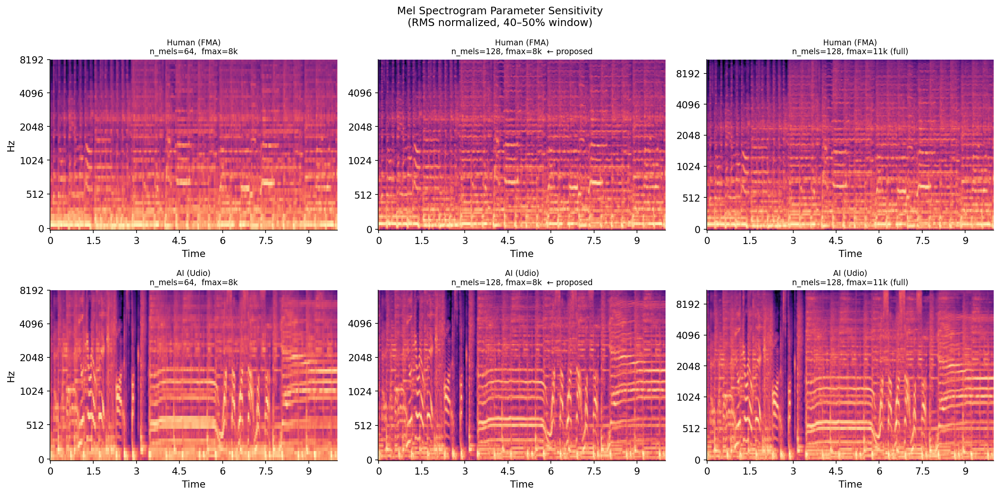

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# One human and one AI track for comparison
human_track = usable[usable["label"] == "human"].sample(1, random_state=7).iloc[0]
ai_track    = usable[usable["label"] == "ai"].sample(1, random_state=7).iloc[0]

human_audio = rms_normalize(get_middle_chunk(human_track))
ai_audio    = rms_normalize(get_middle_chunk(ai_track))

configs = [
    {"n_mels": 64,  "fmax": 8000,  "label": "n_mels=64,  fmax=8k"},
    {"n_mels": 128, "fmax": 8000,  "label": "n_mels=128, fmax=8k  ← proposed"},
    {"n_mels": 128, "fmax": 11025, "label": "n_mels=128, fmax=11k (full)"},
]

for col, cfg in enumerate(configs):
    for row, (audio, track_label) in enumerate([(human_audio, "Human (FMA)"),
                                                 (ai_audio,   "AI (Udio)")]):
        S = librosa.feature.melspectrogram(
            y=audio, sr=SR,
            n_mels=cfg["n_mels"], n_fft=N_FFT,
            hop_length=HOP_LEN, fmax=cfg["fmax"]
        )
        S_db = librosa.power_to_db(S, ref=np.max)
        ax   = axes[row, col]
        librosa.display.specshow(S_db, sr=SR, hop_length=HOP_LEN,
                                 x_axis="time", y_axis="mel",
                                 fmax=cfg["fmax"], ax=ax, cmap="magma")
        ax.set_title(f"{track_label}\n{cfg['label']}", fontsize=9)
        if col > 0:
            ax.set_ylabel("")

plt.suptitle("Mel Spectrogram Parameter Sensitivity\n(RMS normalized, 40–50% window)",
             fontsize=12)
plt.tight_layout()
plt.show()

**Resolution (n_mels=64 vs. 128):**  
64 Mel bins produce a visibly blurred harmonic representation, 
merging overtone series that should be distinct. 128 bins provide 
sufficient frequency resolution to preserve the fine harmonic 
structure necessary for distinguishing acoustic instrument resonances 
from neural vocoder synthesis patterns.

**Frequency Range (fmax=8kHz vs. 11kHz):**  
Extending to 11kHz reveals additional high-frequency structure in 
AI-generated tracks — most visibly horizontal banding artifacts in 
Udio spectrograms. However, this difference requires careful 
interpretation: FMA tracks originate from the Free Music Archive and 
were likely distributed as MP3s before re-encoding to WAV. MP3 
compression introduces a characteristic hard frequency cutoff 
(typically at 16kHz, but visible as reduced energy from ~15kHz 
downward) that could produce an apparent high-frequency gap in human 
tracks unrelated to musical content. If this encoding difference 
drives the observed high-frequency divergence, including frequencies 
above 8kHz would introduce a **codec confounder** rather than a 
genuine synthesis artifact.

**Decision:** The following cell investigates the high-frequency 
energy profiles of each source to determine whether the above-8kHz 
difference reflects a true synthesis fingerprint or a dataset 
encoding artifact before committing to a final fmax value.

#  High Frequency Energy Analysis & Codec Check

In [40]:
from scipy.signal import welch

# ── How many Suno tracks do we have? ─────────────────────────────────────
n_suno = len(usable[usable["source_name"] == "Suno"])
print(f"Suno tracks available: {n_suno}")
print(f"→ Using {n_suno} tracks per source for balanced comparison\n")

np.random.seed(SEED)
balanced_sample = pd.concat([
    usable[usable["source_name"] == "FMA"].sample(n_suno,  random_state=SEED),
    usable[usable["source_name"] == "Suno"].sample(n_suno, random_state=SEED),
    usable[usable["source_name"] == "Udio"].sample(n_suno, random_state=SEED),
]).reset_index(drop=True)

print(f"Balanced sample: {len(balanced_sample)} tracks total")
print(balanced_sample.groupby("source_name").size().rename("tracks").to_string())

# ── Feature extraction ────────────────────────────────────────────────────
def spectral_profile(file_path, sr=SR, chunk_samples=CHUNK_SAMPLES):
    try:
        audio, _ = librosa.load(file_path, sr=sr, mono=True,
                                offset=int(0.40 * sf.info(file_path).duration),
                                duration=chunk_samples / sr)
        if len(audio) < chunk_samples * 0.8:
            return None
        audio = rms_normalize(audio)

        freqs, psd = welch(audio, fs=sr, nperseg=2048)

        def band_energy(f_low, f_high):
            mask = (freqs >= f_low) & (freqs < f_high)
            return float(np.mean(psd[mask])) if mask.sum() > 0 else 0.0

        total = band_energy(20, sr // 2) + 1e-30
        return {
            "sub_bass":    band_energy(20,    250),
            "low_mid":     band_energy(250,   2000),
            "high_mid":    band_energy(2000,  4000),
            "presence":    band_energy(4000,  8000),
            "air":         band_energy(8000,  11025),
            "ultra":       band_energy(11025, sr // 2),
            # Ratios — normalize out absolute loudness differences
            "air_ratio":   band_energy(8000,  11025) / total,
            "ultra_ratio": band_energy(11025, sr // 2) / total,
            "hf_slope":    band_energy(8000,  sr // 2) / (band_energy(2000, 8000) + 1e-10),
            # Full PSD for curve plots
            "_freqs": freqs,
            "_psd":   psd,
        }
    except Exception as e:
        return None

print("\nExtracting spectral profiles...")
profile_rows = []
psd_curves   = {"FMA": [], "Suno": [], "Udio": []}   # for PSD overlay

for i, row in balanced_sample.iterrows():
    result = spectral_profile(row["file_path"])
    if result:
        psd_curves[row["source_name"]].append(result.pop("_psd"))
        freqs_ref = result.pop("_freqs")
        result["source_name"] = row["source_name"]
        result["label"]       = row["label"]
        profile_rows.append(result)

    if (i + 1) % (n_suno) == 0:
        print(f"  {i+1}/{len(balanced_sample)} done")

prof_df = pd.DataFrame(profile_rows)

# ── Summary table ─────────────────────────────────────────────────────────
print("\n=== Mean band energy by source (equal n per source) ===")
band_cols = ["sub_bass", "low_mid", "high_mid", "presence",
             "air", "ultra", "air_ratio", "ultra_ratio", "hf_slope"]
print(prof_df.groupby("source_name")[band_cols].mean().round(6).to_string())


# ── Statistical tests — pairwise per band ────────────────────────────────
from scipy.stats import ttest_ind

fma  = prof_df[prof_df["source_name"] == "FMA"]["hf_slope"]
suno = prof_df[prof_df["source_name"] == "Suno"]["hf_slope"]
udio = prof_df[prof_df["source_name"] == "Udio"]["hf_slope"]

print("\n=== Pairwise t-tests on HF slope ===")
for (n1, d1), (n2, d2) in [
    (("FMA",  fma),  ("Suno", suno)),
    (("FMA",  fma),  ("Udio", udio)),
    (("Suno", suno), ("Udio", udio)),
]:
    t, p = ttest_ind(d1, d2)
    sig  = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "n.s."
    print(f"  {n1} vs {n2}: p={p:.3e}  {sig}")

Suno tracks available: 182
→ Using 182 tracks per source for balanced comparison

Balanced sample: 546 tracks total
source_name
FMA     182
Suno    182
Udio    182

Extracting spectral profiles...
  182/546 done
  364/546 done
  546/546 done

=== Mean band energy by source (equal n per source) ===
             sub_bass   low_mid  high_mid  presence  air  ultra  air_ratio  ultra_ratio  hf_slope
source_name                                                                                      
FMA          0.000022  0.000002       0.0       0.0  0.0    0.0   0.044683          0.0  0.200970
Suno         0.000027  0.000002       0.0       0.0  0.0    0.0   0.015128          0.0  0.326769
Udio         0.000022  0.000002       0.0       0.0  0.0    0.0   0.021741          0.0  0.192103

=== Pairwise t-tests on HF slope ===
  FMA vs Suno: p=2.981e-02  *
  FMA vs Udio: p=8.650e-01  n.s.
  Suno vs Udio: p=3.488e-05  ***


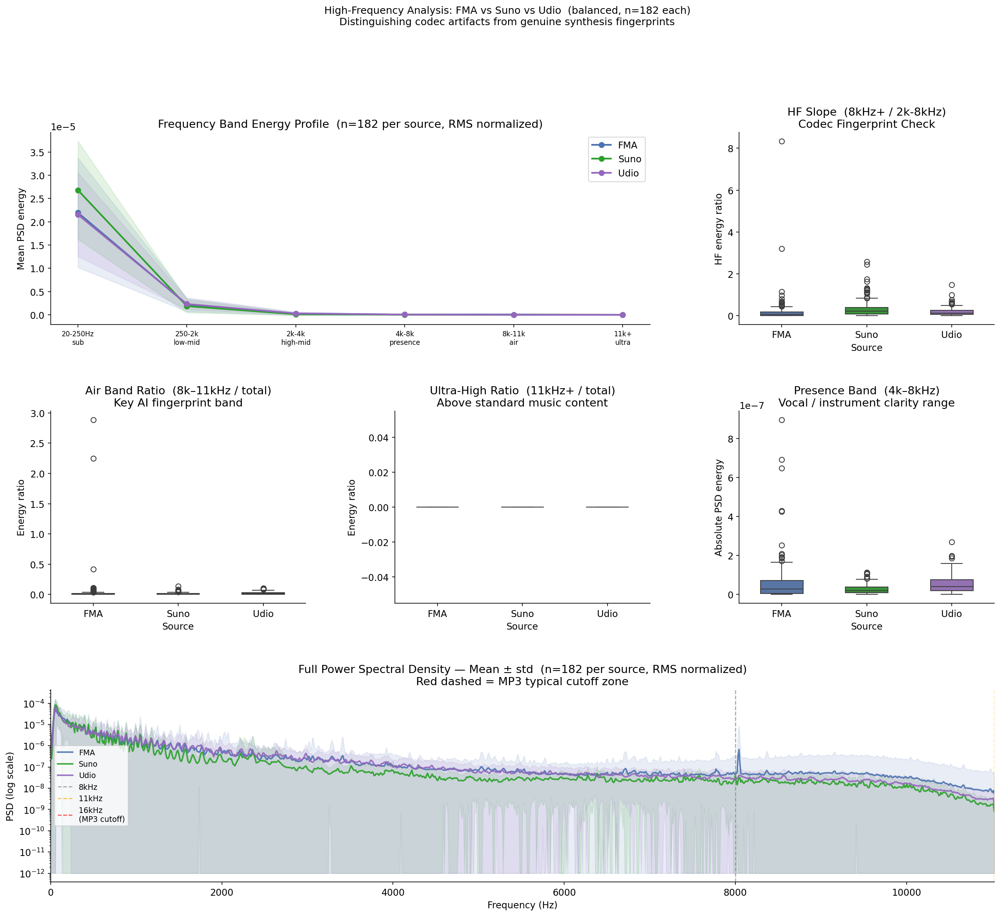

Saved → eda_08_hf_analysis_balanced.png


In [ ]:
fig = plt.figure(figsize=(20, 16))
gs  = fig.add_gridspec(3, 3, hspace=0.45, wspace=0.35)

source_order  = ["FMA", "Suno", "Udio"]
source_colors = {"FMA": "#4C72B0", "Suno": "#2ca02c", "Udio": "#9467bd"}
band_names    = ["sub_bass", "low_mid", "high_mid", "presence", "air", "ultra"]
band_labels   = ["20-250Hz\nsub", "250-2k\nlow-mid", "2k-4k\nhigh-mid",
                 "4k-8k\npresence", "8k-11k\nair", "11k+\nultra"]
x             = np.arange(len(band_names))

# ── 1. Band energy profile (mean lines) ──────────────────────────────────
ax1 = fig.add_subplot(gs[0, :2])
for src in source_order:
    subset = prof_df[prof_df["source_name"] == src]
    means  = subset[band_names].mean().values
    stds   = subset[band_names].std().values
    ax1.plot(x, means, marker="o", color=source_colors[src],
             label=src, linewidth=2.0)
    ax1.fill_between(x, means - stds, means + stds,
                     alpha=0.12, color=source_colors[src])
ax1.set_xticks(x)
ax1.set_xticklabels(band_labels, fontsize=8)
ax1.set_title(f"Frequency Band Energy Profile  (n={n_suno} per source, RMS normalized)")
ax1.set_ylabel("Mean PSD energy")
ax1.legend()

# ── 2. HF slope boxplot ───────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 2])
sns.boxplot(data=prof_df, x="source_name", y="hf_slope",
            order=source_order,
            palette=source_colors, ax=ax2, width=0.5)
ax2.set_title("HF Slope  (8kHz+ / 2k-8kHz)\nCodec Fingerprint Check")
ax2.set_xlabel("Source")
ax2.set_ylabel("HF energy ratio")

# ── 3. Air band ratio per source ─────────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
sns.boxplot(data=prof_df, x="source_name", y="air_ratio",
            order=source_order,
            palette=source_colors, ax=ax3, width=0.5)
ax3.set_title("Air Band Ratio  (8k–11kHz / total)\nKey AI fingerprint band")
ax3.set_xlabel("Source")
ax3.set_ylabel("Energy ratio")

# ── 4. Ultra-high ratio per source ───────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
sns.boxplot(data=prof_df, x="source_name", y="ultra_ratio",
            order=source_order,
            palette=source_colors, ax=ax4, width=0.5)
ax4.set_title("Ultra-High Ratio  (11kHz+ / total)\nAbove standard music content")
ax4.set_xlabel("Source")
ax4.set_ylabel("Energy ratio")

# ── 5. Presence band ratio ────────────────────────────────────────────────
ax5 = fig.add_subplot(gs[1, 2])
sns.boxplot(data=prof_df, x="source_name", y="presence",
            order=source_order,
            palette=source_colors, ax=ax5, width=0.5)
ax5.set_title("Presence Band  (4k–8kHz)\nVocal / instrument clarity range")
ax5.set_xlabel("Source")
ax5.set_ylabel("Absolute PSD energy")

# ── 6. Full PSD overlay per source ───────────────────────────────────────
ax6 = fig.add_subplot(gs[2, :])
for src in source_order:
    curves = psd_curves[src]
    if not curves:
        continue
    arr      = np.array(curves)
    mean_psd = arr.mean(axis=0)
    std_psd  = arr.std(axis=0)
    ax6.semilogy(freqs_ref, mean_psd,
                 color=source_colors[src], label=src,
                 linewidth=1.8, alpha=0.9)
    ax6.fill_between(freqs_ref,
                     np.maximum(mean_psd - std_psd, 1e-12),
                     mean_psd + std_psd,
                     alpha=0.12, color=source_colors[src])

for xline, xlabel, xcolor in [
    (8000,  "8kHz",  "gray"),
    (11025, "11kHz", "orange"),
    (16000, "16kHz\n(MP3 cutoff)", "red"),
]:
    ax6.axvline(xline, color=xcolor, linestyle="--",
                linewidth=1.2, alpha=0.7, label=xlabel)

ax6.set_xlim(0, SR // 2)
ax6.set_xlabel("Frequency (Hz)")
ax6.set_ylabel("PSD (log scale)")
ax6.set_title(f"Full Power Spectral Density — Mean ± std  "
              f"(n={n_suno} per source, RMS normalized)\n"
              f"Red dashed = MP3 typical cutoff zone")
ax6.legend(fontsize=9)

plt.suptitle(
    f"High-Frequency Analysis: FMA vs Suno vs Udio  "
    f"(balanced, n={n_suno} each)\n"
    f"Distinguishing codec artifacts from genuine synthesis fingerprints",
    fontsize=12, y=1.01
)
plt.show()


- Pairwise HF Slope Variance: The t-tests reveal that Suno is a significant statistical outlier (p<0.001 vs. Udio; p=0.029 vs. FMA) regarding high-frequency energy.

- Udio vs. FMA Convergence: Crucially, there is no significant difference between FMA (Human) and Udio (p=0.865) in the HF slope. This suggests that the high-frequency "brightness" observed in previous cells is a specific characteristic of Suno’s synthesis engine rather than a universal "AI signature."

- Spectral Density (PSD) Curves: The full PSD overlay confirms that all three sources exhibit a similar roll-off toward the 16kHz MP3 cutoff zone, suggesting that the FMA tracks do not suffer from a uniquely aggressive codec "hard-cut" compared to the AI outputs.


Key Insights:

- The "Air" Band Disparity: Suno shows a notably higher Air Band Ratio (8k–11kHz). This is likely a result of Suno's specific neural vocoder architecture, which tends to over-generate energy in the upper frequencies.

- Codec Confounder Risk: Since Udio and FMA share nearly identical high-frequency profiles, using a very high f 
max
​	
  (e.g., 11kHz or 12kHz) might lead the model to "cheat" by over-identifying Suno tracks based solely on brightness, while potentially failing to distinguish Udio from Human music.

Final Preprocessing Decision:

To ensure the model learns structural and timbral differences rather than just "brightness" levels, we will adopt f 
max
​	
 8,000 Hz with n 
mels
​	
 =128. This range is high enough to capture the unique "Air" artifacts found in Suno without making the classification task trivial or susceptible to high-frequency noise/codec differences that do not generalize across all AI models.

## 1. Summary of EDA Findings

Systematic analysis across 6,544 usable tracks (1,490 FMA human, 
182 Suno, 4,872 Udio) identified statistically significant 
differences between human and AI-generated music across multiple 
acoustic dimensions. Equally important, the analysis revealed 
dataset-level biases that must be neutralized before training to 
prevent the model from learning spurious shortcuts.

**Macro-Acoustic Biases (must be neutralized):**  
Human tracks show significantly higher RMS energy (mean 0.175 vs 
0.126, p=4.87e-15) and wider dynamic range (0.237 vs 0.192, 
p=3.73e-08). Without normalization, the model risks functioning as 
a loudness detector rather than a music authenticity classifier. 
RMS normalization to a fixed target energy is a mandatory 
preprocessing step.

**Temporal Edge Artifacts (must be removed):**  
Waveform inspection confirmed systematic differences at track 
boundaries: human tracks exhibit engineered fade-ins and fade-outs 
(silence ratio 0.41 pre-trim vs 0.20 for AI), while AI tracks reach 
full energy almost immediately. A percentile-based sampling window 
(25–75% of track duration) removes these boundary artifacts without 
requiring a fixed-second trim that would be disproportionately 
aggressive on short AI tracks.

**Genuine Spectral Discriminators (usable signal):**  
After controlling for the above biases, three spectral features 
show statistically robust separation. Spectral centroid, bandwidth, and 
rolloff confirm that AI music concentrates more energy 
in higher frequencies — consistent with neural vocoder synthesis 
characteristics. 
Transient sharpness (visible in mel spectrograms as narrower vertical 
streaks in FMA vs broader, phase-incoherent transients in Udio/Suno) 
represents an additional discriminator that CNN filters should 
naturally capture.

**Source-Level Caveat:**  
MusicSet (4,740 tracks) was entirely discarded — all tracks fall 
below the 17-second minimum threshold after safety trimming. The 
remaining AI data is dominated by Udio (4,872 tracks) with Suno 
underrepresented (182 tracks).

---

## 2. The Challenge of Confounding Factors

As documented in *"AI-Generated Music Detection and its Challenges"* 
(Deezer Research, 2025), the primary obstacle in this domain is 
**genre confounding**: a classifier trained on an unbalanced dataset 
may learn to distinguish "Electronic" from "Folk" rather than 
"AI-synthesized" from "human-performed." Based on our EDA it is quite possible that 
genre and synthesis method can be partially correlated in this dataset.

The Deezer team attempted to address confounding through autoencoder 
re-synthesis: human tracks were passed through a generative model to 
produce acoustically similar "near-human" AI counterparts, enabling 
pairwise training that forces the classifier to focus on synthesis 
artifacts rather than genre. While conceptually sound, this approach 
showed limited generalizability to high-fidelity generators. Modern 
systems such as Suno and Udio are built on large-scale diffusion and 
transformer architectures whose synthesis artifacts are qualitatively 
different from — and far more subtle than — those produced by the 
basic autoencoders used to construct the training pairs. A model 
trained to detect autoencoder artifacts transfers poorly to 
diffusion-model artifacts.

---

## 3. Alternative Methodology: MERT-Driven Pairwise Training

To close the generalization gap identified in the Deezer study, this 
work proposes a **semantic hard-negative mining** strategy using MERT 
(Music undERstanding Transformer) embeddings as the matching backbone.

**Acoustic Matching via MERT Embeddings:**  
Rather than generating synthetic music, MERT embeddings encode each 
track's musical semantics — genre, mood, instrumentation, and 
harmonic content — into a dense representation. For each human track, 
the nearest AI-generated neighbor in embedding space is identified as 
its training pair. This ensures that paired examples are 
acoustically similar in content, so the classifier cannot exploit 
genre or instrumentation differences as shortcuts.

**Pairwise Discriminative Training:**  
Training on MERT-matched pairs forces the model to identify 
differences that persist after controlling for musical content — 
primarily the spectral texture, phase coherence, and dynamic range 
compression signatures identified in this EDA. Because the pairs are 
matched on semantic similarity rather than synthetic reconstruction, 
they reflect the actual artifact profile of state-of-the-art 
generators rather than simplified autoencoder outputs.

**Generalization Evaluation:**  
Model robustness will be tested on a held-out set of Suno tracks 
generated from diverse natural-language prompts, completely unseen 
during training. This evaluation is intentionally adversarial: Suno 
is underrepresented in the training distribution, so strong 
performance on this set would indicate the model has learned 
generator-agnostic synthesis artifacts rather than Udio-specific 
patterns. Per-source performance breakdowns (FMA vs Suno vs Udio) 
will be reported to make the generalizability analysis explicit.